# 03 · NASA IMERG (GPM) — dictionary, statistics and comparison with POWER

**Product:** `GPM_3IMERGDF` v07 (IMERG *Final Run*, daily, 0.1° ≈ 10 km). Public record 2000-06-01 → 2025-09-30. Free, needs an Earthdata Login.

**What this notebook does**
1. Setup and login (token typed at run time, never saved).
2. **Variable dictionary** built from the real file (every variable, dimensions, units, range, % missing).
3. Extraction for the 9 sites: **all spatial variables at the site pixel** plus **rainfall statistics over 5×5 and 11×11 pixel windows** (0.5° and 1.1° boxes, the scale of one POWER cell). Resumable.
4. Descriptive statistics and graphs of IMERG alone (quality, distribution, seasonality, persistence, extremes, uncertainty, spatial heterogeneity).
5. Inferential tests and the comparison with POWER (totals, day alignment, area mean vs point, paired tests, bootstrap).
6. Multi-year tests (trend) that run only when enough years are stored.

All results print as text tables and are also drawn as figures saved to `../figures/imerg_*.png`.

**Known limits (NASA product notes).** Satellite rain is less skilled over complex terrain, frozen surfaces and coasts, and changes in the satellite constellation can create artefacts in multi-year changes. IMERG days are UTC days.

## 1 · Setup and login

In [4]:
import sys, os, re, time, getpass, warnings
from pathlib import Path
sys.path.append("../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import climate_tools as ct
warnings.filterwarnings("ignore")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 80)

try:
    import earthaccess, xarray as xr
except ImportError as e:
    raise ImportError("Run:  %pip install earthaccess xarray netcdf4 h5netcdf h5py  inside a notebook cell and restart the kernel.") from e

SITES = {
    "Ipiales":   (0.83,  -77.64, 2900), "Nairobi":   (-1.29,  36.82, 1795), "Sorriso":   (-12.54, -55.71, 380),
    "Des Moines": (41.60, -93.61, 290), "Ludhiana":  (30.90,  75.85,  247), "Niamey":    (13.51,   2.11,  220),
    "Can Tho":   (10.03, 105.78,    2), "Mendoza":   (-32.89, -68.84, 750), "Fallon":    (39.47, -118.78, 1240),
}
DATA_DIRS = ["../data", "data", "../notebooks/data", "notebooks/data"]
OUT = Path("../data"); OUT.mkdir(exist_ok=True)
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
IMERG_CSV = OUT / "imerg_final_daily_allvars.csv"

def show(obj, title=None, digits=2):
    if title: print("\n" + title + "\n" + "-" * len(title))
    ff = lambda v: (f"{v:.2e}" if (v != 0 and abs(v) < 1e-3) else f"{v:.{digits}f}")
    print(obj.to_string(float_format=ff) if isinstance(obj, (pd.DataFrame, pd.Series)) else obj)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"imerg_{name}.png", dpi=130, bbox_inches="tight"); plt.show()

if not os.environ.get("EARTHDATA_TOKEN"):
    os.environ["EARTHDATA_TOKEN"] = getpass.getpass("Earthdata token (input hidden): ").strip()
auth = earthaccess.login(strategy="environment")
print("authenticated:", bool(auth.authenticated))

Earthdata token (input hidden):  ········


authenticated: True


## 2 · Variable dictionary (built from the real file)

IMERG daily files hold several variables, not only rain. This cell opens one day (2024-03-15), reads **every** variable once and prints a dictionary: name, dimensions, units, description, and for that global day the % of missing pixels, minimum, maximum and mean.
It reads the whole file once, so it can take about a minute. Paste the output so the variables can be interpreted before the long extraction.

In [5]:
def open_ds(fileobj):
    try:
        ds = xr.open_dataset(fileobj, engine="h5netcdf")
        if "precipitation" not in ds: raise KeyError("precipitation")
    except KeyError:
        ds = xr.open_dataset(fileobj, engine="h5netcdf", group="Grid")
    return ds

def spatial_vars(ds):
    return [v for v in ds.data_vars if {"lat", "lon"} <= set(ds[v].dims) <= {"time", "lat", "lon"}]

def date_of(granule):
    return pd.to_datetime(re.search(r"3IMERG\.(\d{8})", granule.data_links()[0]).group(1))

t0 = time.time()
test = earthaccess.search_data(short_name="GPM_3IMERGDF", version="07", temporal=("2024-03-15", "2024-03-15"))
assert len(test) == 1, "expected exactly one daily granule; check login/date"
ds = open_ds(earthaccess.open(test)[0])
rows = []
for name, v in ds.data_vars.items():
    arr = np.asarray(v.values, float) if v.dtype.kind in "fiu" else None
    rows.append({"variable": name, "dims": ",".join(v.dims), "shape": "x".join(map(str, v.shape)), "dtype": str(v.dtype),
                 "units": v.attrs.get("units", ""), "description": (v.attrs.get("long_name") or v.attrs.get("standard_name") or "")[:70],
                 "%missing": 100 * np.isnan(arr).mean() if arr is not None else np.nan,
                 "min": np.nanmin(arr) if arr is not None else np.nan, "max": np.nanmax(arr) if arr is not None else np.nan,
                 "mean": np.nanmean(arr) if arr is not None else np.nan})
DICT = pd.DataFrame(rows).set_index("variable")
show(DICT, "IMERG daily Final v07 — variables in the file", 3)
print("\ncoordinates:", {k: (len(ds[k]), float(ds[k].min()), float(ds[k].max())) for k in ds.coords if ds[k].ndim == 1 and k != "time"})
print("spatial variables that will be extracted:", spatial_vars(ds))
keep = {k: str(v)[:110] for k, v in ds.attrs.items() if k.lower() in ("title", "shortname", "version", "longname", "processing_level", "institution", "history", "doi", "temporalcoverage")}
show(pd.Series(keep), "selected file attributes")
ds.close(); print("\nelapsed %.0f s" % (time.time() - t0))

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]


IMERG daily Final v07 — variables in the file
---------------------------------------------
                                        dims        shape           dtype    units                                                             description  %missing   min        max    mean
variable                                                                                                                                                                                     
precipitation                   time,lon,lat  1x3600x1800         float32   mm/day  Daily mean precipitation rate (combined microwave-IR) estimate. Former     0.148 0.000    813.560   1.930
precipitation_cnt               time,lon,lat  1x3600x1800            int8    count     Count of all valid half-hourly precipitation retrievals for the day     0.000 0.000     48.000  47.762
precipitation_cnt_cond          time,lon,lat  1x3600x1800            int8    count  Count of half-hourly precipitation retrievals for the day where

**How to read the dictionary.** `precipitation` is the daily rain (mm/day). The other variables are, according to NASA's product documentation, support fields:
valid-sample counts (how many of the 48 half-hours entered the day), a random-error estimate, and the probability that precipitation is liquid. The printed table is the authority; interpret each variable by its `units` and `description`.

## 3 · Extraction for the 9 sites (resumable)

For every day the file is opened once and, for each site:
* **Rain**: value at the site pixel (`P_center`), mean / standard deviation / maximum over the 5×5 window (0.5°, comparable to one POWER cell: `P_mean5`, `P_sd5`, `P_max5`, `P_wet5` = share of pixels ≥ 1 mm), and mean / standard deviation over 11×11 (`P_mean11`, `P_sd11`).
* **Every other spatial variable** at the site pixel.

Results are appended to `data/imerg_final_daily_allvars.csv`; dates already stored are skipped, so it can be stopped and resumed. Files are processed from the most recent date backwards, so an interrupted run still leaves the latest years complete.

In [6]:
def block(ds, var, i0, j0, half):
    da = ds[var]
    if "time" in da.dims: da = da.isel(time=0)
    a, b = max(i0 - half, 0), max(j0 - half, 0)
    da = da.isel(lat=slice(a, i0 + half + 1), lon=slice(b, j0 + half + 1)).transpose("lat", "lon")
    return np.asarray(da.values, float), i0 - a, j0 - b

def extract_file(fileobj, sites=SITES, half=5, only_precip=False):
    ds = open_ds(fileobj); li, lo_i = ds.indexes["lat"], ds.indexes["lon"]
    others = [] if only_precip else [v for v in spatial_vars(ds) if v != "precipitation"]
    rows = []
    for n, (la, lo, el) in sites.items():
        i0 = int(li.get_indexer([la], method="nearest")[0]); j0 = int(lo_i.get_indexer([lo], method="nearest")[0])
        b, ci, cj = block(ds, "precipitation", i0, j0, half)
        w5 = b[max(ci - 2, 0):ci + 3, max(cj - 2, 0):cj + 3]
        r = {"site": n, "cell_lat": float(li[i0]), "cell_lon": float(lo_i[j0]),
             "P_center": b[ci, cj], "P_mean5": np.nanmean(w5), "P_sd5": np.nanstd(w5), "P_max5": np.nanmax(w5),
             "P_wet5": float(np.nanmean(w5 >= 1)), "P_mean11": np.nanmean(b), "P_sd11": np.nanstd(b)}
        for v in others:
            bb, c1, c2 = block(ds, v, i0, j0, 0); r[v] = bb[0, 0]
        rows.append(r)
    ds.close(); return pd.DataFrame(rows)

# timing test on the one-day granule: rain only vs all variables
t0 = time.time(); a = extract_file(earthaccess.open(test)[0], only_precip=True); t_p = time.time() - t0
t0 = time.time(); a = extract_file(earthaccess.open(test)[0]); t_all = time.time() - t0
print(f"one file: rain only {t_p:.1f} s | all variables + windows {t_all:.1f} s")
show(a.set_index("site"), "sample (2024-03-15)", 3)

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

one file: rain only 7.5 s | all variables + windows 11.9 s

sample (2024-03-15)
-------------------
            cell_lat  cell_lon  P_center  P_mean5  P_sd5  P_max5  P_wet5  P_mean11  P_sd11  precipitation_cnt  precipitation_cnt_cond  MWprecipitation  MWprecipitation_cnt  MWprecipitation_cnt_cond  randomError  randomError_cnt  probabilityLiquidPrecipitation
site                                                                                                                                                                                                                                                               
Ipiales        0.850   -77.650     0.525    0.723  0.916   3.305   0.200     0.818   1.046             48.000                   2.000            0.200               12.000                     1.000       28.111           48.000                         100.000
Nairobi       -1.250    36.850     0.375    0.483  0.854   3.250   0.200     0.166   0.525             48.000           

In [7]:
from concurrent.futures import ThreadPoolExecutor
START, END = "2024-01-01", "2024-12-31"        # <- widen later (record: 2000-06-01 .. 2025-09-30)
BATCH = 30
ONLY_PRECIP = False                            # True = rain + windows only (faster if "all variables" is much slower in the timing test)

done = set(pd.read_csv(IMERG_CSV, usecols=["date"])["date"].unique()) if IMERG_CSV.exists() else set()
granules = earthaccess.search_data(short_name="GPM_3IMERGDF", version="07", temporal=(START, END))
todo = [g for g in granules if date_of(g).strftime("%Y-%m-%d") not in done]
todo.sort(key=date_of, reverse=True)
print(f"granules in window: {len(granules)} | already stored: {len(granules) - len(todo)} | to download: {len(todo)}")

def process(args):
    g, f = args
    d = date_of(g).strftime("%Y-%m-%d")
    try:
        df = extract_file(f, only_precip=ONLY_PRECIP); df.insert(0, "date", d); return df
    except Exception as e:
        return ("ERROR", d, repr(e)[:200])

errors, t0 = [], time.time()
for i in range(0, len(todo), BATCH):
    chunk = todo[i:i + BATCH]
    files = earthaccess.open(chunk)
    with ThreadPoolExecutor(max_workers=2) as ex:
        res = list(ex.map(process, zip(chunk, files)))
    good = [r for r in res if isinstance(r, pd.DataFrame)]
    errors += [r for r in res if not isinstance(r, pd.DataFrame)]
    if good:
        new = pd.concat(good)
        if IMERG_CSV.exists():   # keep a stable column set if the file already exists
            cols = pd.read_csv(IMERG_CSV, nrows=0).columns; new = new.reindex(columns=cols)
        new.to_csv(IMERG_CSV, mode="a", header=not IMERG_CSV.exists(), index=False)
    print(f"{i + len(chunk)}/{len(todo)} days | {time.time() - t0:.0f} s elapsed | errors so far: {len(errors)}")
print("finished. errors:", errors[:5])

granules in window: 366 | already stored: 120 | to download: 246


QUEUEING TASKS | :   0%|          | 0/30 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/30 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/30 [00:00<?, ?it/s]

30/246 days | 345 s elapsed | errors so far: 0


QUEUEING TASKS | :   0%|          | 0/30 [00:00<?, ?it/s]

... (23 outputs left out)

QUEUEING TASKS | :   0%|          | 0/6 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/6 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/6 [00:00<?, ?it/s]

246/246 days | 2596 s elapsed | errors so far: 0
finished. errors: []


## 4 · Load stored data and check quality

In [8]:
im = pd.read_csv(IMERG_CSV, parse_dates=["date"]).drop_duplicates(["date", "site"]).sort_values(["site", "date"])
extra_cols = [c for c in im.columns if c not in ("date", "site", "cell_lat", "cell_lon") and not c.startswith("P_")]
span_years = (im.date.max() - im.date.min()).days / 365.25
print("records:", len(im), "| days:", im.date.nunique(), "|", im.date.min().date(), "→", im.date.max().date(), f"| span {span_years:.1f} years")
print("other variables stored:", extra_cols)

R = {n: im[im.site == n].set_index("date")["P_center"].asfreq("D") for n in SITES}
q = pd.DataFrame({n: {"days stored": int(R[n].notna().sum()), "gaps (days)": int(R[n].isna().sum()),
                      "cell_lat": im[im.site == n].cell_lat.iloc[0], "cell_lon": im[im.site == n].cell_lon.iloc[0],
                      "site_lat": SITES[n][0], "site_lon": SITES[n][1]} for n in SITES}).T
show(q, "completeness and pixel used", 2)
cnt_cols = [c for c in extra_cols if "cnt" in c.lower() and "cond" not in c.lower()]
for c in cnt_cols:
    t = im.groupby("site")[c].agg(["min", "median", "max"]); t["days <48 valid"] = im.groupby("site")[c].apply(lambda s: int((s < 48).sum()))
    show(t, f"valid half-hourly samples per day ({c})", 1)

records: 3294 | days: 366 | 2024-01-01 → 2024-12-31 | span 1.0 years
other variables stored: ['precipitation_cnt', 'precipitation_cnt_cond', 'MWprecipitation', 'MWprecipitation_cnt', 'MWprecipitation_cnt_cond', 'randomError', 'randomError_cnt', 'probabilityLiquidPrecipitation']

completeness and pixel used
---------------------------
            days stored  gaps (days)  cell_lat  cell_lon  site_lat  site_lon
Ipiales          366.00         0.00      0.85    -77.65      0.83    -77.64
Nairobi          366.00         0.00     -1.25     36.85     -1.29     36.82
Sorriso          366.00         0.00    -12.55    -55.75    -12.54    -55.71
Des Moines       366.00         0.00     41.65    -93.65     41.60    -93.61
Ludhiana         366.00         0.00     30.85     75.85     30.90     75.85
Niamey           366.00         0.00     13.55      2.15     13.51      2.11
Can Tho          366.00         0.00     10.05    105.75     10.03    105.78
Mendoza          366.00         0.00    -32.85  

## 5 · Descriptive statistics of daily rain (site pixel)


Daily rain, IMERG site pixel
----------------------------
             days  mean_mm_day  median   std  skew  kurtosis   p90   p99    max  total_mm_yr  mean_wet_mm(>=1)  wet>=0.1mm_%  wet>=1mm_%  wet>=5mm_%  wet>=10mm_%  wet>=25mm_%
Ipiales    366.00         4.55    0.47 10.90  4.96     32.29 14.47 54.07 100.96      1661.22             10.20         56.83       43.99       21.04        13.11         3.55
Nairobi    366.00         5.72    1.77  9.87  3.16     12.99 16.03 48.23  79.27      2088.74              9.20         78.14       61.20       29.51        16.39         5.74
Sorriso    366.00         4.58    0.02  9.52  2.88      8.60 15.29 42.85  56.77      1672.96             12.18         47.54       37.16       23.22        14.75         5.74
Des Moines 366.00         2.94    0.00  8.80  5.50     41.32  8.30 37.77  95.33      1074.26             11.73         38.52       24.59       14.48         9.02         3.28
Ludhiana   366.00         1.92    0.00  8.00  7.00     57.62  3.03

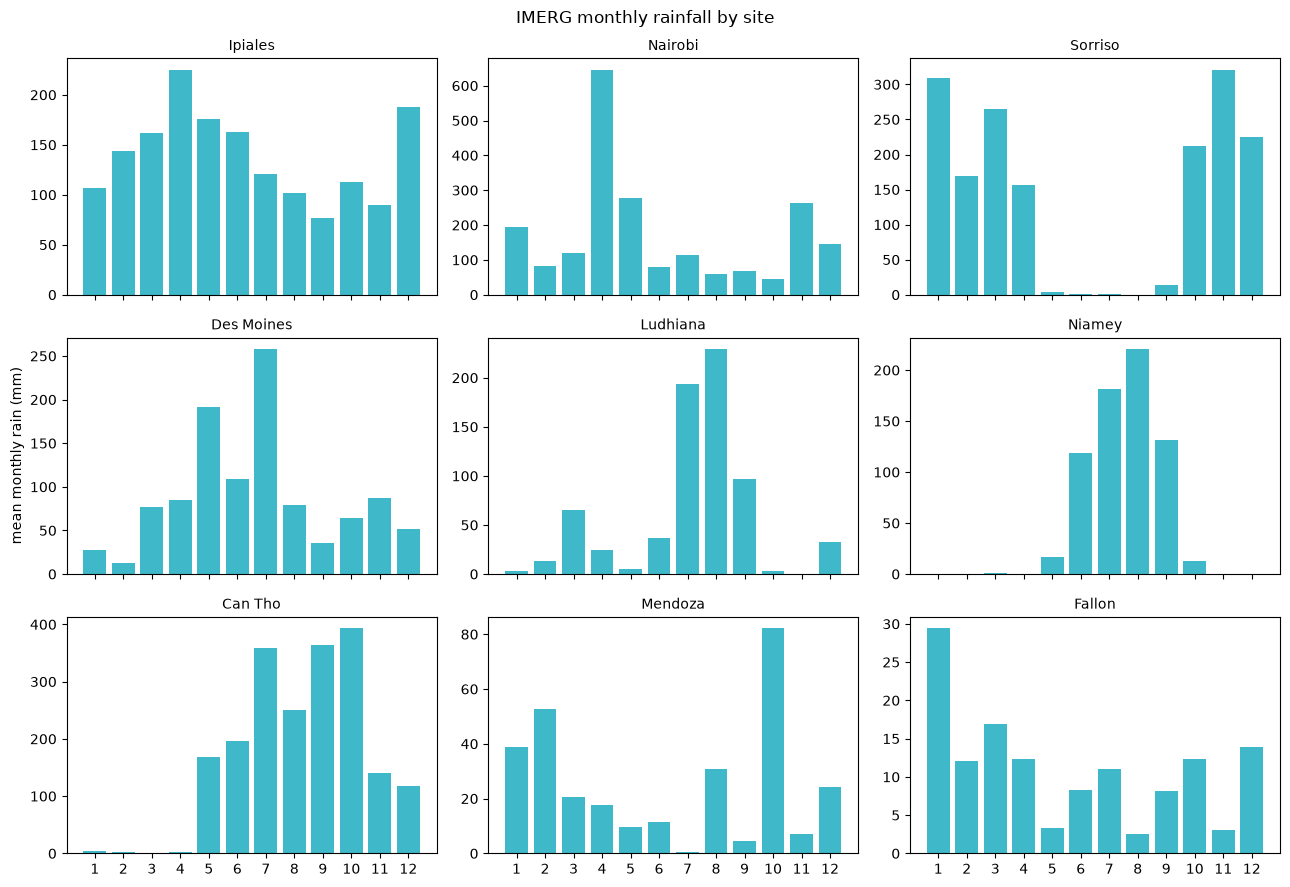

In [9]:
rows = {}
for n in SITES:
    s = R[n].dropna()
    d = {"days": len(s), "mean_mm_day": s.mean(), "median": s.median(), "std": s.std(), "skew": stats.skew(s), "kurtosis": stats.kurtosis(s),
         "p90": s.quantile(.90), "p99": s.quantile(.99), "max": s.max(), "total_mm_yr": s.mean() * 365.25,
         "mean_wet_mm(>=1)": s[s >= 1].mean()}
    for thr in (0.1, 1, 5, 10, 25): d[f"wet>={thr}mm_%"] = 100 * (s >= thr).mean()
    rows[n] = d
DESC = pd.DataFrame(rows).T
show(DESC, "Daily rain, IMERG site pixel", 2)

fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
for ax, n in zip(axes.ravel(), SITES):
    s = R[n].dropna(); m = s.resample("MS").sum().groupby(lambda d: d.month).mean()
    ax.bar(m.index, m.values, color="#3FB8C9"); ax.set_title(n, fontsize=10); ax.set_xticks(range(1, 13))
axes[1, 0].set_ylabel("mean monthly rain (mm)"); fig.suptitle("IMERG monthly rainfall by site")
savefig("01_monthly_by_site")

## 6 · Distribution of wet-day amounts

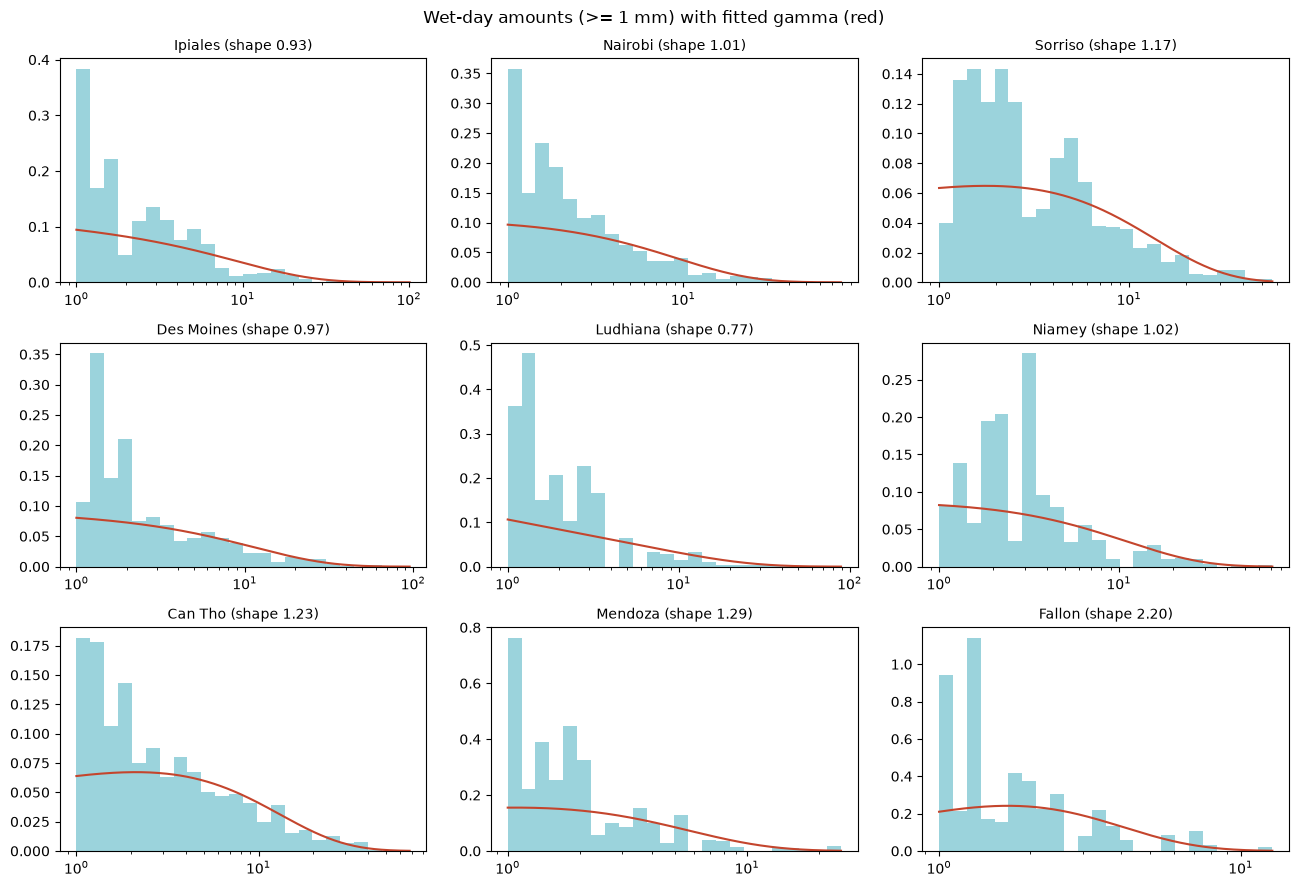


Gamma fit to wet-day amounts (KS stat: smaller = better fit)
------------------------------------------------------------
            wet_day_freq  mean_wet_intensity  median_wet_intensity  p95_wet  gamma_shape  gamma_scale  ks_stat  wet days
Ipiales            0.440              10.197                 4.790   37.120        0.927       11.000    0.156   161.000
Nairobi            0.612               9.203                 4.717   30.034        1.012        9.090    0.118   224.000
Sorriso            0.372              12.176                 7.255   38.803        1.169       10.416    0.095   136.000
Des Moines         0.246              11.734                 6.467   33.298        0.971       12.081    0.096    90.000
Ludhiana           0.186              10.137                 3.325   46.135        0.767       13.214    0.214    68.000
Niamey             0.169              10.875                 4.745   32.479        1.020       10.657    0.160    62.000
Can Tho            0.473      

In [10]:
rows = {}
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, n in zip(axes.ravel(), SITES):
    s = R[n].dropna(); wet = s[s >= 1]
    if len(wet) < 20: rows[n] = {"wet days": len(wet)}; ax.set_title(f"{n}: too few wet days"); continue
    r = ct.wet_day_stats(s, 1.0); r["wet days"] = len(wet); rows[n] = r
    ax.hist(wet, bins=np.logspace(0, np.log10(max(wet.max(), 2)), 25), density=True, color="#9bd3dc"); ax.set_xscale("log")
    xs = np.logspace(0, np.log10(max(wet.max(), 2)), 200); ax.plot(xs, stats.gamma.pdf(xs, r["gamma_shape"], 0, r["gamma_scale"]), color="#C4452D")
    ax.set_title(f"{n} (shape {r['gamma_shape']:.2f})", fontsize=10)
fig.suptitle("Wet-day amounts (>= 1 mm) with fitted gamma (red)"); savefig("02_wetday_gamma")
show(pd.DataFrame(rows).T, "Gamma fit to wet-day amounts (KS stat: smaller = better fit)", 3)

## 7 · Seasonality (inferential)

Kruskal–Wallis test: does the distribution of daily rain differ among calendar months? `eta2_H` is the effect size (share of rank variation explained by month). With less than 3 years the "seasonal share of variance" is not computed (it would be circular).

In [11]:
rows = {}
for n in SITES:
    s = R[n].dropna()
    try: H, p, e2 = ct.kruskal_by_month(s)
    except Exception: H, p, e2 = np.nan, np.nan, np.nan
    mm = s.resample("MS").sum()
    r = {"KW_H": H, "KW_p": p, "eta2_H": e2, "wettest_month": int(s.groupby(s.index.month).sum().idxmax()), "driest_month": int(s.groupby(s.index.month).sum().idxmin())}
    if span_years >= 3 and len(mm) >= 36:
        r["seasonal_share_monthly_var"] = 1 - (mm - mm.groupby(mm.index.month).transform("mean")).var() / mm.var()
    rows[n] = r
show(pd.DataFrame(rows).T, "Seasonality of daily rain", 3)


Seasonality of daily rain
-------------------------
              KW_H     KW_p  eta2_H  wettest_month  driest_month
Ipiales     18.757    0.066   0.022          4.000         9.000
Nairobi     98.462 3.60e-16   0.247          4.000        10.000
Sorriso    197.139 2.92e-36   0.526         11.000         8.000
Des Moines  24.587    0.010   0.038          7.000         2.000
Ludhiana    83.879 2.61e-13   0.206          8.000        11.000
Niamey     129.253 2.47e-22   0.334          8.000         1.000
Can Tho    211.469 3.08e-39   0.566         10.000         3.000
Mendoza     53.172 1.67e-07   0.119         10.000         7.000
Fallon      39.473 4.40e-05   0.080          1.000         8.000


## 8 · Persistence: do rainy days come in streaks?


Persistence of rainy days (wet = >= 1 mm)
-----------------------------------------
            P(wet|wet)  P(wet|dry)  markov_chi2_p  acf_lag1  acf_lag2  LjungBox_p  dry_spell_mean_d  dry_spell_max_d  wet_spell_mean_d  wet_spell_max_d
Ipiales          0.609       0.304       1.06e-08     0.154     0.021       0.284             3.254           13.000             2.556            8.000
Nairobi          0.723       0.433       5.50e-08     0.606     0.508   1.79e-125             2.290            7.000             3.613           22.000
Sorriso          0.691       0.179       3.42e-22     0.135     0.272    2.97e-19             5.476          133.000             3.238           12.000
Des Moines       0.404       0.196       1.26e-04     0.327     0.024    3.43e-06             5.111           24.000             1.667            4.000
Ludhiana         0.456       0.125       7.42e-10     0.170     0.086    1.98e-07             7.842           76.000             1.838            8.000
Nia

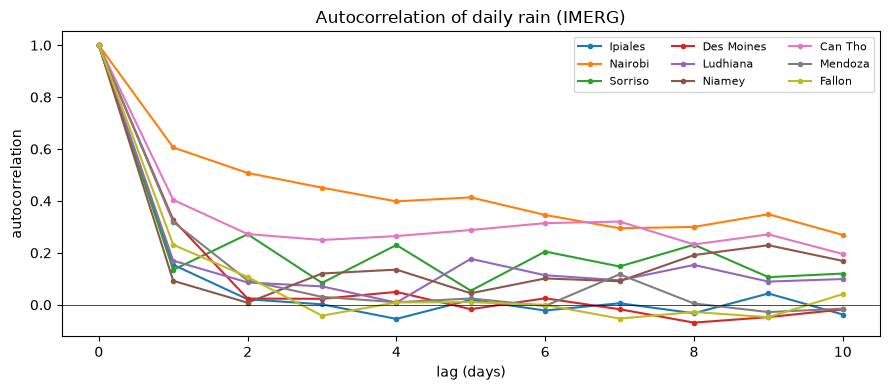

In [12]:
def runs(b):
    out, c = [], 0
    for v in b:
        if v: c += 1
        elif c: out.append(c); c = 0
    if c: out.append(c)
    return np.array(out)

rows, acfs = {}, {}
for n in SITES:
    s = R[n]; w = (s >= 1).astype(float).where(s.notna())
    prev, nxt = w.shift(1), w
    ok = prev.notna() & nxt.notna()
    t = pd.crosstab(prev[ok], nxt[ok]).reindex(index=[0.0, 1.0], columns=[0.0, 1.0], fill_value=0)
    pww = t.loc[1.0, 1.0] / max(t.loc[1.0].sum(), 1); pwd = t.loc[0.0, 1.0] / max(t.loc[0.0].sum(), 1)
    chi_p = stats.chi2_contingency(t.values + 0)[1] if (t.values.sum() > 0 and (t.values.sum(axis=0) > 0).all() and (t.values.sum(axis=1) > 0).all()) else np.nan
    x = s.dropna().values; a = ct.acf(x, 10); acfs[n] = a
    lb = ct.ljung_box(x, 10)
    dry, wet = runs((s < 1).values & s.notna().values), runs((s >= 1).values)
    rows[n] = {"P(wet|wet)": pww, "P(wet|dry)": pwd, "markov_chi2_p": chi_p, "acf_lag1": a[1], "acf_lag2": a[2], "LjungBox_p": lb[1],
               "dry_spell_mean_d": dry.mean() if len(dry) else np.nan, "dry_spell_max_d": dry.max() if len(dry) else np.nan,
               "wet_spell_mean_d": wet.mean() if len(wet) else np.nan, "wet_spell_max_d": wet.max() if len(wet) else np.nan}
show(pd.DataFrame(rows).T, "Persistence of rainy days (wet = >= 1 mm)", 3)
fig, ax = plt.subplots(figsize=(9, 4))
for n in SITES: ax.plot(range(0, 11), acfs[n], marker="o", ms=3, label=n)
ax.axhline(0, color="k", lw=.5); ax.set_xlabel("lag (days)"); ax.set_ylabel("autocorrelation"); ax.legend(ncol=3, fontsize=8); ax.set_title("Autocorrelation of daily rain (IMERG)")
savefig("03_acf")

## 9 · Extremes

In [13]:
rows, tops = {}, {}
for n in SITES:
    s = R[n].dropna(); ann = s.groupby(s.index.year).agg(["max", "count"]); ann = ann[ann["count"] >= 330]["max"]
    r = {"max_mm_day": s.max(), "days>=25.4": int((s >= 25.4).sum()), "days>=50": int((s >= 50).sum()), "days>=100": int((s >= 100).sum()), "full_years": len(ann)}
    if len(ann) >= 8:
        res, _ = ct.annual_max_return_levels(ann.values, periods=(5, 10, 25), B=500)
        for T, (v, lo, hi) in res.items(): r[f"{T}yr_level"] = v; r[f"{T}yr_CI"] = f"{lo:.0f}-{hi:.0f}"
    rows[n] = r; tops[n] = s.nlargest(3)
show(pd.DataFrame(rows).T, "Extreme daily rain (return levels need >= 8 full years)", 1)
show(pd.concat(tops, names=["site", "date"]).round(1).to_frame("mm/day"), "three largest days per site", 1)


Extreme daily rain (return levels need >= 8 full years)
-------------------------------------------------------
            max_mm_day  days>=25.4  days>=50  days>=100  full_years
Ipiales          101.0        13.0       5.0        1.0         1.0
Nairobi           79.3        20.0       3.0        0.0         1.0
Sorriso           56.8        20.0       2.0        0.0         1.0
Des Moines        95.3        10.0       3.0        0.0         1.0
Ludhiana          89.0         7.0       4.0        0.0         1.0
Niamey            71.3         6.0       2.0        0.0         1.0
Can Tho           67.6        21.0       1.0        0.0         1.0
Mendoza           24.7         0.0       0.0        0.0         1.0
Fallon            12.7         0.0       0.0        0.0         1.0

three largest days per site
---------------------------
                       mm/day
site       date              
Ipiales    2024-04-22   101.0
           2024-06-16    94.3
           2024-02-05    55.9


## 10 · Other variables in the file (uncertainty and phase)

Descriptive table for every extra variable stored at the site pixel. If the file includes a random-error estimate and a liquid-precipitation probability, the next cell also summarises them:
relative error on wet days, and the share of days likely to be solid precipitation.

In [14]:
if not extra_cols:
    print("No extra variables were stored (extraction ran with rain only).")
else:
    show(im.groupby("site")[extra_cols].agg(["mean", "min", "max"]).round(2), "extra variables at the site pixel (mean / min / max)", 2)
    err = [c for c in extra_cols if "error" in c.lower() and "cnt" not in c.lower()]
    liq = [c for c in extra_cols if "liquid" in c.lower()]
    rows = {}
    for n in SITES:
        d = im[im.site == n]; wet = d[d.P_center >= 1]; r = {}
        if err and len(wet): rel = wet[err[0]] / wet.P_center; r.update({"median_error/rain_wet": rel.median(), "share_wet_days_error>rain_%": 100 * (rel > 1).mean(), "corr(rain,error)": d.P_center.corr(d[err[0]])})
        if liq and len(d): r.update({"mean_prob_liquid_%": d[liq[0]].mean(), "days_prob_liquid<50": int((d[liq[0]] < 50).sum())})
        rows[n] = r
    if any(rows.values()): show(pd.DataFrame(rows).T, "uncertainty and phase", 2)


extra variables at the site pixel (mean / min / max)
----------------------------------------------------
           precipitation_cnt             precipitation_cnt_cond            MWprecipitation             MWprecipitation_cnt            MWprecipitation_cnt_cond            randomError               randomError_cnt             probabilityLiquidPrecipitation             
                        mean   min   max                   mean  min   max            mean  min    max                mean  min   max                     mean  min   max        mean  min      max            mean   min   max                           mean   min    max
site                                                                                                                                                                                                                                                                       
Can Tho                48.00 48.00 48.00                  10.09 0.00 46.00            6.1

## 11 · Spatial heterogeneity: is one pixel representative of its neighbourhood?

Compares the site pixel with the mean of the 5×5 window (0.5°, about one POWER cell) and the 11×11 window (1.1°). `CV5` is the day-to-day spread across the 5×5 pixels relative to their mean; a large value means rain varies strongly over short distances (typical of mountains).
The Wilcoxon test checks whether the site pixel is systematically wetter or drier than its 5×5 mean on days when the neighbourhood has rain.


Site pixel vs neighbourhood
---------------------------
            total_center_mm_yr  total_mean5_mm_yr  total_mean11_mm_yr  center/mean5  CV5_rainy_days  share_pixels_wet5_%  Wilcoxon_p
Ipiales               1661.219           1733.168            1969.454         0.958           1.009               65.642    1.84e-06
Nairobi               2088.741           1723.846            1540.543         1.212           1.085               61.552    3.31e-04
Sorriso               1672.965           1666.105            1667.972         1.004           0.646               80.612       0.074
Des Moines            1074.259           1106.952            1100.298         0.970           0.522               80.991       0.009
Ludhiana               700.741            675.480             680.366         1.037           0.835               72.286       0.154
Niamey                 682.049            704.117             719.744         0.969           0.669               78.880       0.021
Can Tho     

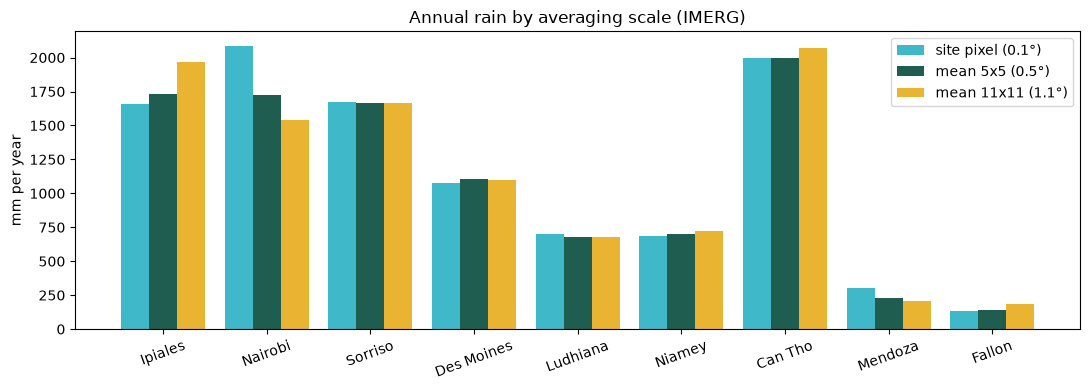

In [15]:
rows = {}
for n in SITES:
    d = im[im.site == n].set_index("date"); rainy = d[d.P_mean5 >= 0.5]
    w = stats.wilcoxon(rainy.P_center, rainy.P_mean5) if len(rainy) > 20 and (rainy.P_center - rainy.P_mean5).abs().sum() > 0 else None
    rows[n] = {"total_center_mm_yr": d.P_center.mean() * 365.25, "total_mean5_mm_yr": d.P_mean5.mean() * 365.25, "total_mean11_mm_yr": d.P_mean11.mean() * 365.25,
               "center/mean5": d.P_center.sum() / d.P_mean5.sum(), "CV5_rainy_days": (rainy.P_sd5 / rainy.P_mean5).mean(),
               "share_pixels_wet5_%": 100 * rainy.P_wet5.mean(), "Wilcoxon_p": w.pvalue if w else np.nan}
HET = pd.DataFrame(rows).T
show(HET, "Site pixel vs neighbourhood", 3)
fig, ax = plt.subplots(figsize=(11, 4)); x = np.arange(len(HET)); wd = .27
ax.bar(x - wd, HET.total_center_mm_yr, wd, label="site pixel (0.1°)", color="#3FB8C9")
ax.bar(x, HET.total_mean5_mm_yr, wd, label="mean 5x5 (0.5°)", color="#1F5D50")
ax.bar(x + wd, HET.total_mean11_mm_yr, wd, label="mean 11x11 (1.1°)", color="#E8B431")
ax.set_xticks(x); ax.set_xticklabels(HET.index, rotation=20); ax.set_ylabel("mm per year"); ax.legend(); ax.set_title("Annual rain by averaging scale (IMERG)")
savefig("04_scale_effect")

## 12 · IMERG vs POWER

For each site: total ratio (IMERG / POWER) using the site pixel, the 5×5 mean and the 11×11 mean; daily and monthly correlation; and, for the site pixel, a **paired test** of monthly totals (Wilcoxon signed-rank; H0: no systematic difference) and a bootstrap 95 % CI of the total ratio (months resampled).
**Day alignment:** correlation between IMERG and POWER shifted by −1, 0 and +1 day. If the best lag is not 0, part of the daily disagreement is a time-offset between the two day definitions.


POWER vs IMERG
--------------
             days  POWER_mm_yr  ratio_pixel  ratio_mean5  ratio_mean11  r_daily_pixel  r_daily_mean5  r_monthly_pixel  r_monthly_mean5  wet_days_POWER_%  wet_days_pixel_%  wet_days_mean5_%  wilcoxon_p_monthly  ratio_CI_lo  ratio_CI_hi
Ipiales    366.00      1183.40         1.40         1.46          1.66           0.27           0.30             0.91             0.95             60.93             43.99             57.10            4.88e-04         1.25         1.67
Nairobi    366.00       674.04         3.10         2.56          2.29           0.42           0.51             0.94             0.95             33.88             61.20             49.18            4.88e-04         2.54         3.84
Sorriso    366.00      1466.90         1.14         1.14          1.14           0.35           0.40             0.88             0.89             58.74             37.16             40.44                0.62         0.87         1.43
Des Moines 366.00       914.6

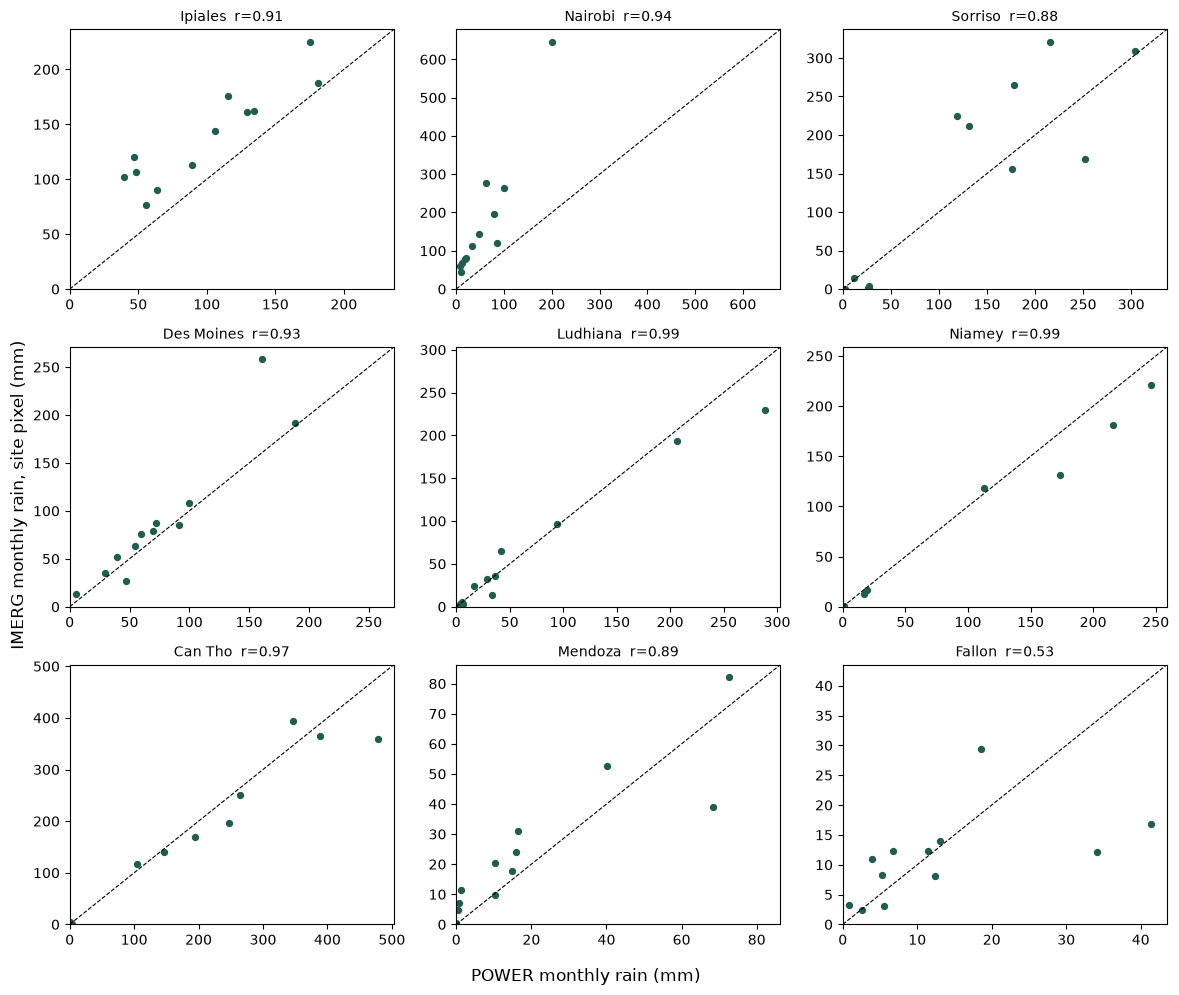

In [16]:
rng = np.random.default_rng(0)
rows, lagrows, monthly = {}, {}, {}
for n, (la, lo, el) in SITES.items():
    p = ct.find_csv(la, lo, DATA_DIRS)
    if p is None: continue
    pw = ct.load_csv(p)["PRECTOTCORR"]; d = im[im.site == n].set_index("date")
    j = pd.concat([pw.rename("POWER"), d.P_center.rename("c"), d.P_mean5.rename("m5"), d.P_mean11.rename("m11")], axis=1, join="inner").dropna()
    if len(j) < 60: continue
    m = j.resample("MS").sum(min_count=20).dropna(); monthly[n] = m
    r = {"days": len(j), "POWER_mm_yr": j.POWER.mean() * 365.25}
    for k, lab in (("c", "pixel"), ("m5", "mean5"), ("m11", "mean11")):
        r[f"ratio_{lab}"] = j[k].sum() / j.POWER.sum()
    r["r_daily_pixel"] = j.POWER.corr(j.c); r["r_daily_mean5"] = j.POWER.corr(j.m5)
    r["r_monthly_pixel"] = m.POWER.corr(m.c) if len(m) > 3 else np.nan; r["r_monthly_mean5"] = m.POWER.corr(m.m5) if len(m) > 3 else np.nan
    r["wet_days_POWER_%"] = 100 * (j.POWER >= 1).mean(); r["wet_days_pixel_%"] = 100 * (j.c >= 1).mean(); r["wet_days_mean5_%"] = 100 * (j.m5 >= 1).mean()
    if len(m) >= 6 and (m.POWER - m.c).abs().sum() > 0:
        r["wilcoxon_p_monthly"] = stats.wilcoxon(m.POWER, m.c).pvalue
        bs = [m.c.iloc[i].sum() / m.POWER.iloc[i].sum() for i in (rng.integers(0, len(m), len(m)) for _ in range(2000))]
        r["ratio_CI_lo"], r["ratio_CI_hi"] = np.percentile(bs, [2.5, 97.5])
    rows[n] = r
    lagrows[n] = {f"lag{k:+d}": j.POWER.shift(k).corr(j.c) for k in (-1, 0, 1)}
CMP = pd.DataFrame(rows).T
show(CMP, "POWER vs IMERG", 2)
LAG = pd.DataFrame(lagrows).T; LAG["best_lag"] = LAG.idxmax(axis=1)
show(LAG, "daily correlation with POWER shifted by k days", 3)

fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for ax, n in zip(axes.ravel(), SITES):
    if n not in monthly: ax.set_title(n + ": no data"); continue
    m = monthly[n]; lim = max(m.POWER.max(), m.c.max()) * 1.05
    ax.scatter(m.POWER, m.c, color="#1F5D50", s=18); ax.plot([0, lim], [0, lim], "k--", lw=.8); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_title(f"{n}  r={m.POWER.corr(m.c):.2f}" if len(m) > 3 else n, fontsize=10)
fig.supxlabel("POWER monthly rain (mm)"); fig.supylabel("IMERG monthly rain, site pixel (mm)"); savefig("05_power_vs_imerg_monthly")

## 13 · Multi-year tests (run only with enough years)

Trend of annual rain (Mann–Kendall via Kendall τ and Theil–Sen slope) in IMERG and in POWER over the **same** years. This answers whether POWER's rain trend at a site is also seen by an independent estimate.
It requires at least 8 complete years; widen `START` in section 3 (it resumes without repeating) to run it.

In [18]:
rows = {}
for n, (la, lo, el) in SITES.items():
    p = ct.find_csv(la, lo, DATA_DIRS)
    s = R[n].dropna(); ann = s.groupby(s.index.year).agg(["sum", "count"]); ann = ann[ann["count"] >= 350]["sum"]
    if p is None or len(ann) < 8: continue
    pw = ct.load_csv(p)["PRECTOTCORR"]; pa = pw.groupby(pw.index.year).sum().reindex(ann.index)
    ti, tp = ct.trend_test(ann.index.values, ann.values), ct.trend_test(pa.index.values, pa.values)
    rows[n] = {"years": len(ann), "IMERG_slope_mm_yr": ti["sen_slope_per_yr"], "IMERG_p": ti["p"], "POWER_slope_mm_yr": tp["sen_slope_per_yr"], "POWER_p": tp["p"],
               "corr_annual": ann.corr(pa)}
if rows:
    T = pd.DataFrame(rows).T
    for col in ("IMERG", "POWER"):   # Holm correction across sites
        p = T[f"{col}_p"].astype(float); order = p.sort_values().index; k = len(p); adj, run = {}, 0.0
        for i, idx in enumerate(order): run = max(run, min(1.0, (k - i) * p[idx])); adj[idx] = run
        T[f"{col}_p_Holm"] = pd.Series(adj)
    show(T, "annual rain trends, same years (Holm = corrected for 9 sites)", 3)
else:
    print("Not enough complete years stored (need >= 8). Extend START in section 3 and rerun.")

Not enough complete years stored (need >= 8). Extend START in section 3 and rerun.


## 14 · What each result means for the platform (fill in after running)

| Question | Where to look | Why it matters |
|---|---|---|
| Which variables does IMERG give us? | Section 2 | Defines what the platform can show and warn about. |
| Do the two sources agree on *when* it rains? | Section 12 (`r_monthly`) | If yes, the monthly calendar can be a headline. |
| Do they agree on *how much*? | `ratio_*`, CI, Wilcoxon | If not, show a range with both sources. |
| Is the gap a scale effect? | `ratio_mean5` vs `ratio_pixel`, Section 11 | If averaging closes the gap, compare like with like. |
| Is part of the daily mismatch a day offset? | `best_lag` | Decides whether to shift one source before comparing days. |
| Is one pixel representative? | Section 11 (`CV5`, Wilcoxon) | Tells how much to trust a point click on the map. |
| Are trends real? | Section 13 | Tells if a trend can be a headline or must stay a caveat. |
| Does IMERG give uncertainty? | Section 10 | Possible confidence band for the farmer. |

In [19]:
# ---- 15 · Export for the platform + two checks (needs sections 1-4 already run)
def _runs(b):
    out, c = [], 0
    for v in b:
        if v: c += 1
        elif c: out.append(c); c = 0
    if c: out.append(c)
    return np.array(out)

monthly_rows, site_rows, agg_rows = [], {}, {}
for n, (la, lo, el) in SITES.items():
    p = ct.find_csv(la, lo, DATA_DIRS)
    if p is None: continue
    pw = ct.load_csv(p)["PRECTOTCORR"]; d = im[im.site == n].set_index("date").sort_index()
    j = pd.concat([pw.rename("POWER_mm"), d.P_center.rename("IMERG_pixel_mm"), d.P_mean5.rename("IMERG_mean5_mm"),
                   d.MWprecipitation.rename("IMERG_microwave_mm")], axis=1, join="inner").dropna(subset=["POWER_mm", "IMERG_pixel_mm"])
    m = j.resample("MS").sum(min_count=20).dropna(subset=["POWER_mm", "IMERG_pixel_mm"])
    rng3 = m[["POWER_mm", "IMERG_pixel_mm", "IMERG_mean5_mm"]]
    m["range_low_mm"], m["range_high_mm"] = rng3.min(axis=1), rng3.max(axis=1)
    m.insert(0, "site", n); monthly_rows.append(m.reset_index().rename(columns={"index": "month", "date": "month"}))

    s = d.P_center; wet = (s >= 1)
    prev = wet.shift(1).fillna(False).astype(bool)
    dry_runs = _runs(~wet.values)
    rain_days = d[d.P_center > 0]
    site_rows[n] = {
        "POWER_mm_yr": j.POWER_mm.mean() * 365.25, "IMERG_pixel_mm_yr": j.IMERG_pixel_mm.mean() * 365.25, "IMERG_mean5_mm_yr": j.IMERG_mean5_mm.mean() * 365.25,
        "IMERG_microwave_mm_yr": j.IMERG_microwave_mm.mean() * 365.25,
        "ratio_pixel_over_POWER": j.IMERG_pixel_mm.sum() / j.POWER_mm.sum(),
        "monthly_rank_corr": stats.spearmanr(m.POWER_mm, m.IMERG_pixel_mm)[0] if len(m) > 3 else np.nan,
        "wet_day_freq_%": 100 * wet.mean(), "P(wet|wet)": (wet & prev).sum() / max(prev.sum(), 1),
        "longest_dry_spell_d": int(dry_runs.max()) if len(dry_runs) else 0, "days_ge_25mm": int((s >= 25.4).sum()), "days_ge_50mm": int((s >= 50).sum()),
        "rain_hours_per_rainy_day": (rain_days["precipitation_cnt_cond"] / 2).mean() if "precipitation_cnt_cond" in d else np.nan,
        "rainy_days_prob_liquid<50": int((rain_days["probabilityLiquidPrecipitation"] < 50).sum()) if "probabilityLiquidPrecipitation" in d else np.nan,
        "rainy_days": len(rain_days),
    }
    r = {}
    for k in (1, 3, 7):
        best = []
        for sh in (-1, 0, 1):
            a = j.POWER_mm.shift(sh).rolling(k).sum().iloc[k::k] if k > 1 else j.POWER_mm.shift(sh)
            b = j.IMERG_pixel_mm.rolling(k).sum().iloc[k::k] if k > 1 else j.IMERG_pixel_mm
            best.append(a.corr(b))
        r[f"r_{k}d_shift0"] = best[1]; r[f"r_{k}d_best"] = max(best); r[f"best_shift_{k}d"] = (-1, 0, 1)[int(np.nanargmax(best))]
    agg_rows[n] = r

SITE_RAIN = pd.DataFrame(site_rows).T
MONTHLY_RAIN = pd.concat(monthly_rows, ignore_index=True)
show(SITE_RAIN, "Rain summary per site (what the platform can show)", 2)
show(pd.DataFrame(agg_rows).T, "Correlation POWER vs IMERG when days are summed (1, 3, 7 days) and the best day shift", 3)
MONTHLY_RAIN.round(2).to_csv(OUT / "platform_rain_monthly.csv", index=False); SITE_RAIN.round(3).to_csv(OUT / "platform_rain_sites.csv")
print("\nsaved: data/platform_rain_monthly.csv, data/platform_rain_sites.csv")


Rain summary per site (what the platform can show)
--------------------------------------------------
            POWER_mm_yr  IMERG_pixel_mm_yr  IMERG_mean5_mm_yr  IMERG_microwave_mm_yr  ratio_pixel_over_POWER  monthly_rank_corr  wet_day_freq_%  P(wet|wet)  longest_dry_spell_d  days_ge_25mm  days_ge_50mm  rain_hours_per_rainy_day  rainy_days_prob_liquid<50  rainy_days
Ipiales         1183.40            1661.22            1733.17                 521.02                    1.40               0.83           43.99        0.61                13.00         13.00          5.00                      3.51                       0.00      231.00
Nairobi          674.04            2088.74            1723.85                3213.03                    3.10               0.92           61.20        0.72                 7.00         20.00          3.00                      6.36                       0.00      296.00
Sorriso         1466.90            1672.96            1666.10                2075.98   